# 08 · PCA y MCA: explicabilidad y reducción de dimensionalidad
## Módulo 3 — Programa Data Science for Business | FUTURA

---

**Entrada:** `06_train_proc` (numéricas escaladas), `03_train` (categóricas crudas) ·
**Salida:** coordenadas/loadings, `artifacts/pca.joblib`, `artifacts/mca.joblib`, `reports/pca_mca.json`.

Dos técnicas hermanas de reducción de dimensionalidad, según el tipo de variable:

| Técnica | Para variables | Análogo |
|---|---|---|
| **PCA** | numéricas | descompone la **varianza** |
| **MCA** | categóricas | descompone la **inercia** de la tabla de contingencia |

Ambas responden: *¿puedo describir a mis clientes con **menos** dimensiones sin perder
demasiado?* Y ambas entregan un **mapa** donde clientes/categorías parecidas quedan cerca.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pipeline_io import (
    TARGET, SEGMENT_COL, SEED, load_stage, save_stage, save_artifact, save_report, save_table,
    set_plot_theme, COLOR_OK, COLOR_BAD, COLOR_NEUTRAL, COLOR_WARN,
)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

set_plot_theme()

train_proc = load_stage("06_train_proc")
y_train = train_proc[TARGET]
X_scaled = train_proc.drop(columns=[TARGET, SEGMENT_COL])

print("Features escaladas:", X_scaled.shape)

Features escaladas: (447, 32)


---
# Parte A · PCA (Análisis de Componentes Principales)

## 8.1 Preparación: solo variables continuas

El PCA maximiza varianza, así que solo tiene sentido sobre variables **continuas** ya
estandarizadas. Las dummies binarias (0/1) y los flags las excluimos: su "varianza" no es
comparable con la de una variable continua.

In [2]:
# Continuas = más de 2 valores distintos (excluye dummies/flags binarios)
continuas = [c for c in X_scaled.columns if X_scaled[c].nunique() > 2]
Xc = X_scaled[continuas]
print(f"Variables continuas para PCA: {len(continuas)}")
print(continuas)

Variables continuas para PCA: 16
['Dependents', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'TotalIncome', 'TotalIncomeByPerson', 'Cuota', '%Cuota', 'LoanToIncome', 'Ratio_Coaplicante', 'log_ApplicantIncome', 'log_CoapplicantIncome', 'log_LoanAmount', 'log_TotalIncome', 'log_Cuota']


## 8.2 Scree plot y varianza explicada acumulada

El **scree plot** muestra cuánta varianza aporta cada componente. Buscamos el **codo** (donde la
curva se aplana) y el nº de componentes que acumula el **80–90%** de la varianza.

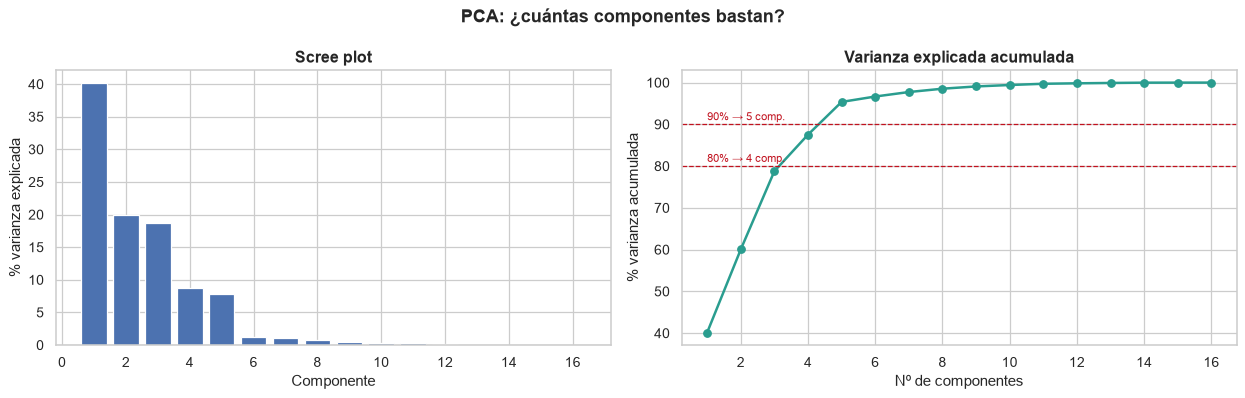

Componentes para 80% de varianza: 4
Componentes para 90% de varianza: 5
De 16 variables → 4 componentes conservan el 80%.


In [3]:
from sklearn.decomposition import PCA

pca = PCA(random_state=SEED).fit(Xc)
var_exp = pca.explained_variance_ratio_
var_acum = np.cumsum(var_exp)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(range(1, len(var_exp) + 1), var_exp * 100, color=COLOR_NEUTRAL)
axes[0].set_xlabel("Componente"); axes[0].set_ylabel("% varianza explicada")
axes[0].set_title("Scree plot")
axes[1].plot(range(1, len(var_acum) + 1), var_acum * 100, "o-", color=COLOR_OK, lw=2)
for umbral in [80, 90]:
    axes[1].axhline(umbral, color=COLOR_WARN, ls="--", lw=1)
    k = np.argmax(var_acum * 100 >= umbral) + 1
    axes[1].text(1, umbral + 1, f"{umbral}% → {k} comp.", fontsize=9, color=COLOR_WARN)
axes[1].set_xlabel("Nº de componentes"); axes[1].set_ylabel("% varianza acumulada")
axes[1].set_title("Varianza explicada acumulada")
plt.suptitle("PCA: ¿cuántas componentes bastan?", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

k80 = int(np.argmax(var_acum >= 0.80) + 1)
k90 = int(np.argmax(var_acum >= 0.90) + 1)
print(f"Componentes para 80% de varianza: {k80}")
print(f"Componentes para 90% de varianza: {k90}")
print(f"De {len(continuas)} variables → {k80} componentes conservan el 80%.")

## 8.3 Proyección 2D (biplot) coloreada por el target

Proyectamos los clientes sobre las 2 primeras componentes. Si los rechazados (1) y aprobados (0)
se separan, hay estructura; si se mezclan, las 2 primeras componentes no capturan el riesgo.

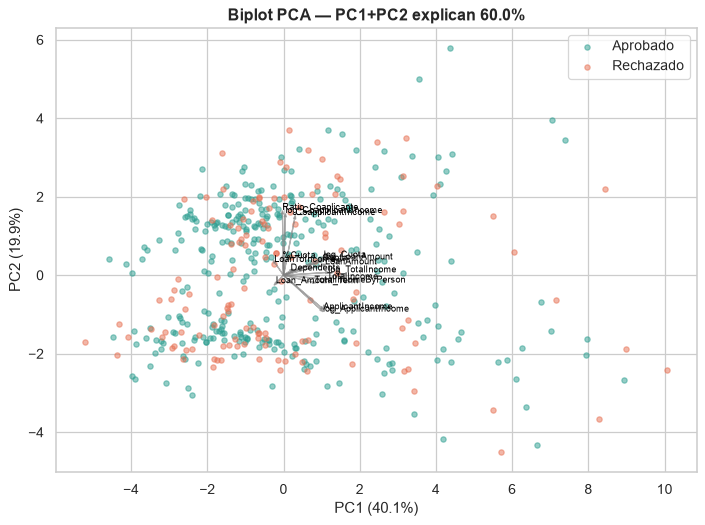

>> PC1 y PC2 juntas explican 60.0%. El resto NO se ve en este plano.


In [4]:
coords = pca.transform(Xc)
fig, ax = plt.subplots(figsize=(8, 6))
for val, col, lab in [(0, COLOR_OK, "Aprobado"), (1, COLOR_BAD, "Rechazado")]:
    m = y_train.values == val
    ax.scatter(coords[m, 0], coords[m, 1], s=18, alpha=0.5, color=col, label=lab)
# vectores de las variables (loadings) sobre el biplot
for i, c in enumerate(continuas):
    ax.arrow(0, 0, pca.components_[0, i] * 3, pca.components_[1, i] * 3,
             color="gray", alpha=0.6, head_width=0.06)
    ax.text(pca.components_[0, i] * 3.2, pca.components_[1, i] * 3.2, c, fontsize=7, color="black")
ax.set_xlabel(f"PC1 ({var_exp[0]:.1%})"); ax.set_ylabel(f"PC2 ({var_exp[1]:.1%})")
ax.set_title(f"Biplot PCA — PC1+PC2 explican {var_acum[1]:.1%}")
ax.legend()
plt.tight_layout()
plt.show()
print(f">> PC1 y PC2 juntas explican {var_acum[1]:.1%}. El resto NO se ve en este plano.")

## 8.4 Matriz de loadings: interpretar las componentes

Los **loadings** son la contribución de cada variable original a cada componente. Es lo que
permite ponerle **nombre** a una componente abstracta.

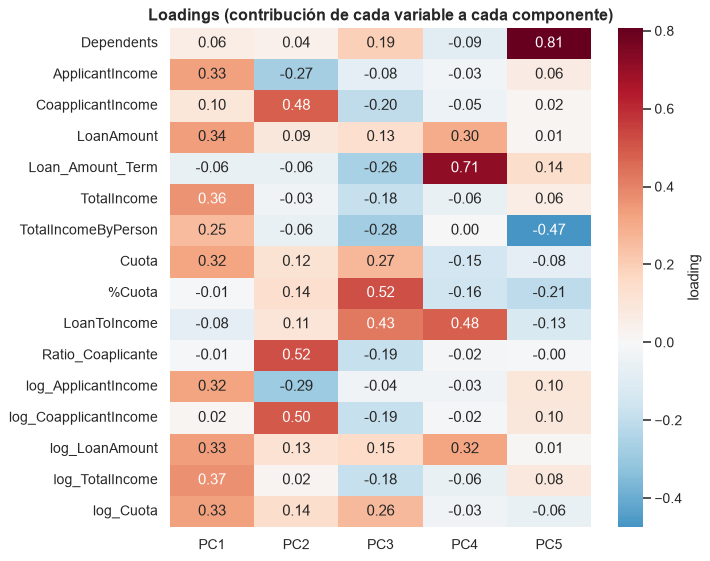

In [5]:
loadings = pd.DataFrame(pca.components_[:k90].T, index=continuas,
                        columns=[f"PC{i+1}" for i in range(k90)])
fig, ax = plt.subplots(figsize=(8, max(4, 0.4 * len(continuas))))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax,
            cbar_kws={"label": "loading"})
ax.set_title("Loadings (contribución de cada variable a cada componente)", fontweight="bold")
plt.tight_layout()
plt.show()

## 8.5 Error de reconstrucción

Cuánta información perdemos al comprimir a *k* componentes y volver a expandir.

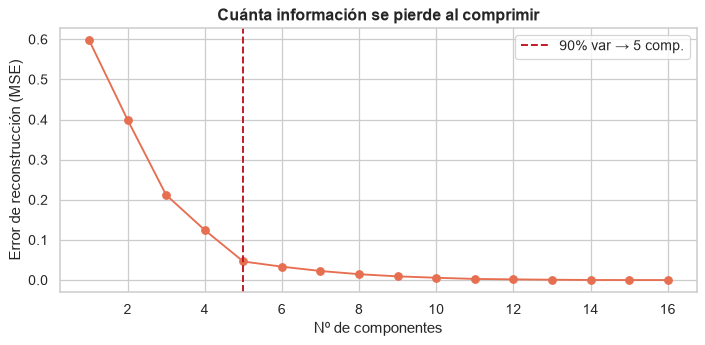

In [6]:
errores = []
for k in range(1, len(continuas) + 1):
    p = PCA(n_components=k, random_state=SEED).fit(Xc)
    recon = p.inverse_transform(p.transform(Xc))
    errores.append(np.mean((Xc.values - recon) ** 2))
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(continuas) + 1), errores, "o-", color=COLOR_BAD)
plt.axvline(k90, color=COLOR_WARN, ls="--", label=f"90% var → {k90} comp.")
plt.xlabel("Nº de componentes"); plt.ylabel("Error de reconstrucción (MSE)")
plt.title("Cuánta información se pierde al comprimir"); plt.legend()
plt.tight_layout()
plt.show()

## 8.6 ⚠️ Discusión honesta: ¿PCA en un modelo de riesgo?

**Casi nunca.** PCA cambia **interpretabilidad por compresión**, y en banca la interpretabilidad
es un **requisito regulatorio**: hay que explicarle al cliente por qué se le rechazó. "Su
componente principal 3 es −1.4" no es una explicación válida ni ante el regulador ni ante el
cliente. PCA se usa cuando hay cientos de variables sin significado individual (sensores), no
aquí. Lo aprendemos, sabemos que existe, y en riesgo lo evitamos.

---
# Parte B · MCA (Análisis de Correspondencias Múltiple)

El **MCA es el PCA de las variables categóricas**. En vez de varianza, descompone la **inercia**
(la dispersión de la tabla de contingencia). Entrega un **mapa** donde las categorías que
**co-ocurren** quedan cerca — la herramienta clásica para entender la estructura de variables
cualitativas.

Entregables que vamos a producir (los que pediste explícitamente):
1. **Mapa de factores** (categorías en el plano de las 2 primeras dimensiones)
2. **Contribución** de cada categoría a cada componente
3. **cos2** (calidad de representación de cada categoría)

In [7]:
import prince

# Categóricas crudas (incluimos Credit_History como categoría, con 'NA' para nulos).
# Alineamos a las MISMAS filas que sobrevivieron al pipeline (06): el NB04 quitó outliers
# del train, así que 03_train tiene más filas que 06. Trabajamos sobre la intersección.
raw = load_stage("03_train").loc[X_scaled.index]
cats = ["Gender", "Married", "Dependents", "Education", "Self_Employed", "Property_Area"]
D = raw[cats].astype("object")
D["Credit_History"] = raw["Credit_History"].map({0.0: "Sin_hist", 1.0: "Con_hist"}).fillna("Desconocido")
D = D.fillna("NA").astype(str)
cats = cats + ["Credit_History"]

print("Variables categóricas para MCA:", cats)
print("Total de categorías (columnas indicadoras):", sum(D[c].nunique() for c in cats))

Variables categóricas para MCA: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area', 'Credit_History']
Total de categorías (columnas indicadoras): 22


## 8.7 Ajuste del MCA e inercia por dimensión

El MCA se ajusta **solo sobre TRAIN**. Las **eigenvalues** son la inercia de cada dimensión; el
**% de inercia** es su peso relativo (análogo al % de varianza del PCA).

dimension  eigenvalue  %_inercia  %_acumulado
     Dim1      0.2366      11.04        11.04
     Dim2      0.2060       9.61        20.66
     Dim3      0.1811       8.45        29.11
     Dim4      0.1704       7.95        37.06
     Dim5      0.1602       7.48        44.54
     Dim6      0.1516       7.07        51.61


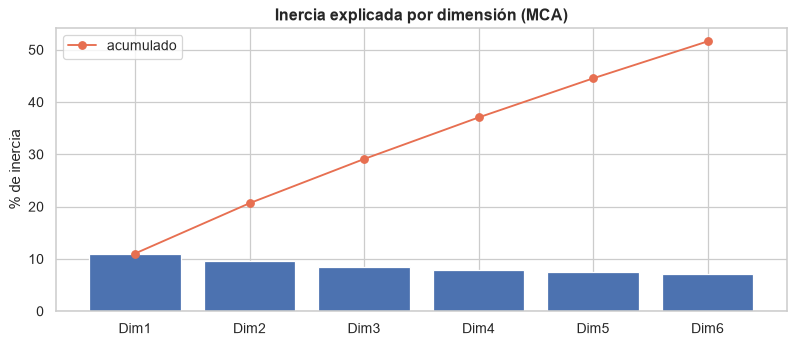

In [8]:
mca = prince.MCA(n_components=6, random_state=SEED).fit(D)

eig = np.asarray(mca.eigenvalues_)
pct = np.asarray(mca.percentage_of_variance_)
pct_acum = np.cumsum(pct)

tabla_dim = pd.DataFrame({
    "dimension": [f"Dim{i+1}" for i in range(len(eig))],
    "eigenvalue": np.round(eig, 4),
    "%_inercia": np.round(pct, 2),
    "%_acumulado": np.round(pct_acum, 2),
})
print(tabla_dim.to_string(index=False))

plt.figure(figsize=(9, 4))
plt.bar(tabla_dim["dimension"], tabla_dim["%_inercia"], color=COLOR_NEUTRAL)
plt.plot(tabla_dim["dimension"], tabla_dim["%_acumulado"], "o-", color=COLOR_BAD, label="acumulado")
plt.ylabel("% de inercia"); plt.title("Inercia explicada por dimensión (MCA)"); plt.legend()
plt.tight_layout()
plt.show()

## 8.8 🗺️ Mapa de factores (el entregable estrella)

Cada punto es una **categoría**. Categorías cercanas **co-ocurren** en los mismos clientes;
categorías lejanas se excluyen. El origen es el "cliente promedio"; cuanto más lejos del centro,
más distintiva es la categoría.

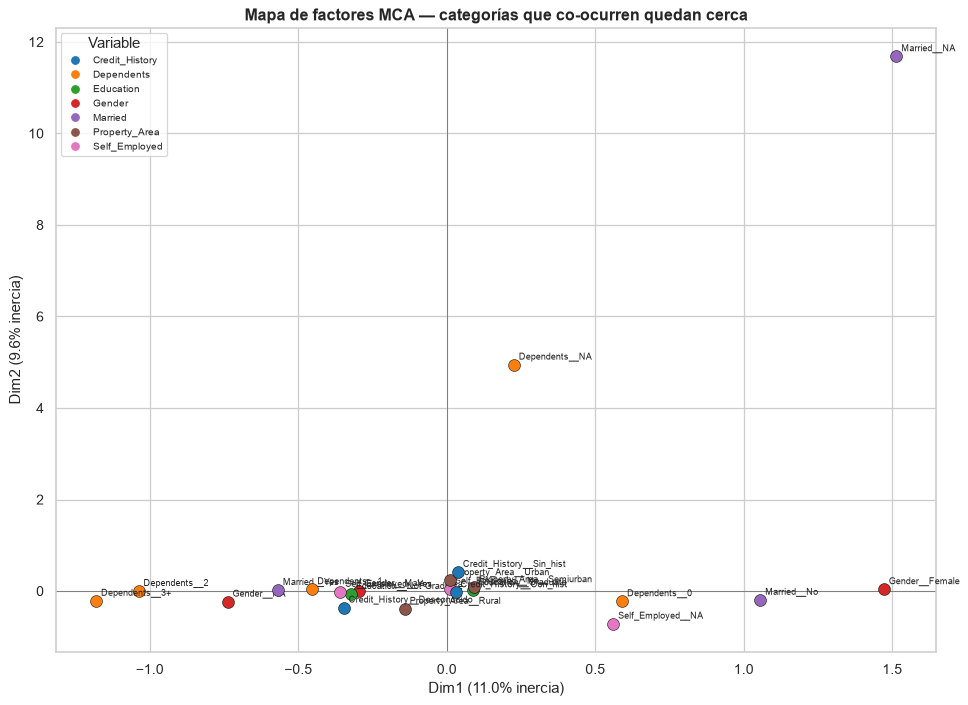

In [9]:
col_coords = mca.column_coordinates(D)
col_coords.columns = [f"Dim{i+1}" for i in range(col_coords.shape[1])]

fig, ax = plt.subplots(figsize=(11, 8))
# color por variable de origen
variables_origen = [idx.split("__")[0] if "__" in idx else idx.split("_")[0] for idx in col_coords.index]
paleta = dict(zip(sorted(set(variables_origen)), sns.color_palette("tab10", len(set(variables_origen)))))
for idx, vo in zip(col_coords.index, variables_origen):
    x, yv = col_coords.loc[idx, "Dim1"], col_coords.loc[idx, "Dim2"]
    ax.scatter(x, yv, s=90, color=paleta[vo], edgecolor="black", linewidth=0.4, zorder=3)
    ax.annotate(idx, (x, yv), fontsize=7.5, xytext=(4, 4), textcoords="offset points")
ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel(f"Dim1 ({pct[0]:.1f}% inercia)"); ax.set_ylabel(f"Dim2 ({pct[1]:.1f}% inercia)")
ax.set_title("Mapa de factores MCA — categorías que co-ocurren quedan cerca", fontweight="bold")
handles = [plt.Line2D([0], [0], marker="o", ls="", color=paleta[v], label=v) for v in paleta]
ax.legend(handles=handles, fontsize=8, title="Variable")
plt.tight_layout()
plt.show()

## 8.9 Contribución de las categorías a cada componente

La **contribución** (en %) dice cuánto aporta cada categoría a construir cada dimensión. Las de
mayor contribución son las que **definen** el eje — su interpretación de negocio.

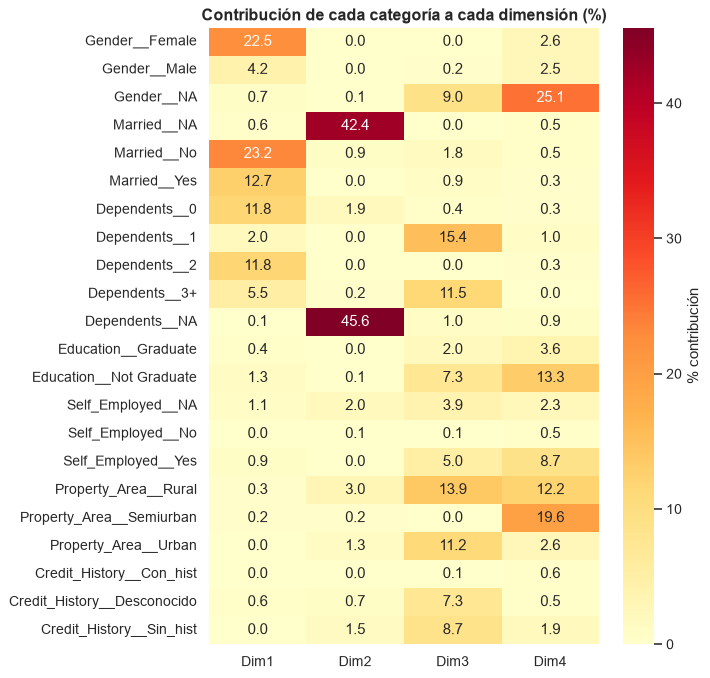

Categorías que MÁS definen cada una de las 2 primeras dimensiones:
  Dim1: Married__No (23.2%) · Gender__Female (22.5%) · Married__Yes (12.7%)
  Dim2: Dependents__NA (45.6%) · Married__NA (42.4%) · Property_Area__Rural (3.0%)


In [10]:
contrib = mca.column_contributions_.copy()
contrib.columns = [f"Dim{i+1}" for i in range(contrib.shape[1])]
contrib_pct = (contrib * 100).round(2)

fig, ax = plt.subplots(figsize=(8, max(5, 0.35 * len(contrib))))
sns.heatmap(contrib_pct.iloc[:, :4], annot=True, fmt=".1f", cmap="YlOrRd", ax=ax,
            cbar_kws={"label": "% contribución"})
ax.set_title("Contribución de cada categoría a cada dimensión (%)", fontweight="bold")
plt.tight_layout()
plt.show()

print("Categorías que MÁS definen cada una de las 2 primeras dimensiones:")
for dim in ["Dim1", "Dim2"]:
    top = contrib_pct[dim].sort_values(ascending=False).head(3)
    print(f"  {dim}: " + " · ".join(f"{i} ({v:.1f}%)" for i, v in top.items()))

## 8.10 cos2: calidad de representación

El **cos2** (coseno cuadrado) mide qué tan **bien representada** está cada categoría en cada
dimensión (0 = mal, 1 = perfecta). Una categoría con cos2 alto en Dim1 está bien explicada por
ese eje; una con cos2 bajo en todas las dimensiones mostradas está "escondida" en dimensiones
superiores y **no hay que sobre-interpretar su posición** en el mapa.

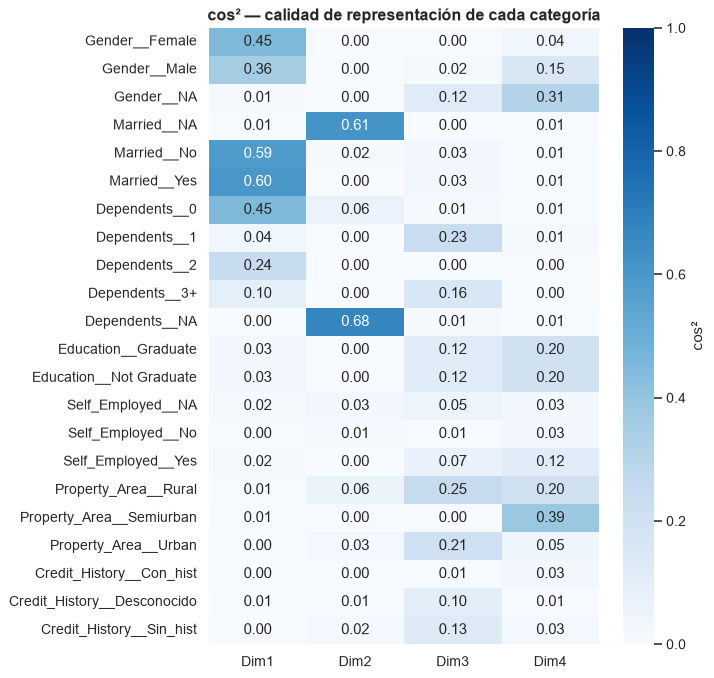

Categorías MEJOR representadas en el mapa 2D (cos² Dim1+Dim2):
Dependents__NA    0.677
Married__NA       0.624
Married__No       0.605
Married__Yes      0.604
Dependents__0     0.514

Categorías PEOR representadas (cuidado al interpretarlas en el mapa):
Credit_History__Con_hist    0.006
Property_Area__Semiurban    0.010
Self_Employed__No           0.013


In [11]:
cos2 = mca.column_cosine_similarities(D).copy()
cos2.columns = [f"Dim{i+1}" for i in range(cos2.shape[1])]

fig, ax = plt.subplots(figsize=(8, max(5, 0.35 * len(cos2))))
sns.heatmap(cos2.iloc[:, :4], annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax,
            cbar_kws={"label": "cos²"})
ax.set_title("cos² — calidad de representación de cada categoría", fontweight="bold")
plt.tight_layout()
plt.show()

# Calidad acumulada en el plano Dim1-Dim2
cos2["calidad_plano_1_2"] = cos2["Dim1"] + cos2["Dim2"]
print("Categorías MEJOR representadas en el mapa 2D (cos² Dim1+Dim2):")
print(cos2["calidad_plano_1_2"].sort_values(ascending=False).head(5).round(3).to_string())
print()
print("Categorías PEOR representadas (cuidado al interpretarlas en el mapa):")
print(cos2["calidad_plano_1_2"].sort_values().head(3).round(3).to_string())

## 8.11 Proyección de clientes coloreada por target

Las coordenadas de fila proyectan a cada **cliente** en el mismo plano. Vemos si el target se
organiza según la estructura categórica.

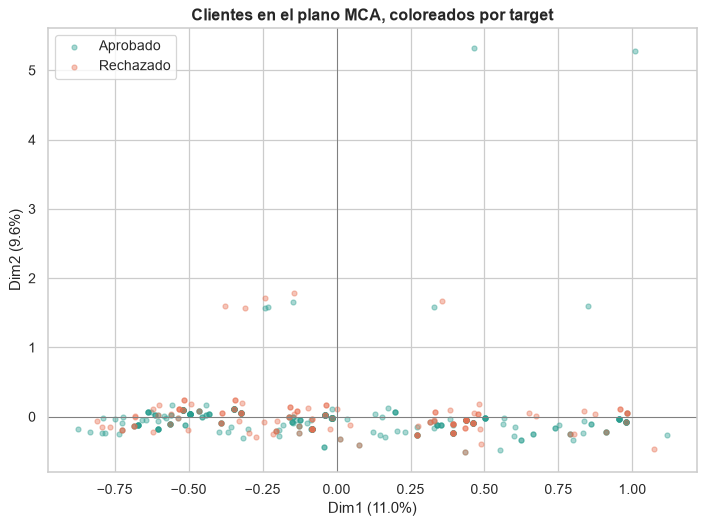

In [12]:
row_coords = mca.row_coordinates(D)
row_coords.columns = [f"Dim{i+1}" for i in range(row_coords.shape[1])]
fig, ax = plt.subplots(figsize=(8, 6))
for val, col, lab in [(0, COLOR_OK, "Aprobado"), (1, COLOR_BAD, "Rechazado")]:
    m = y_train.values == val
    ax.scatter(row_coords.loc[m, "Dim1"], row_coords.loc[m, "Dim2"], s=16, alpha=0.4, color=col, label=lab)
ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel(f"Dim1 ({pct[0]:.1f}%)"); ax.set_ylabel(f"Dim2 ({pct[1]:.1f}%)")
ax.set_title("Clientes en el plano MCA, coloreados por target"); ax.legend()
plt.tight_layout()
plt.show()

## 8.12 Exportación

In [13]:
save_artifact(pca, "pca")
save_artifact(mca, "mca")

# Coordenadas de fila (útiles como features alternativas o para visualización)
pca_coords = pd.DataFrame(coords[:, :k90], index=X_scaled.index,
                          columns=[f"PC{i+1}" for i in range(k90)])
save_stage(pca_coords, "08_pca_coords_train")
save_stage(row_coords.set_index(X_scaled.index), "08_mca_coords_train")

reporte = {
    "pca": {"n_continuas": len(continuas), "k_80": k80, "k_90": k90,
            "var_explicada": [float(v) for v in var_exp[:k90]]},
    "mca": {"n_categoricas": len(cats), "inercia_dim": [float(v) for v in pct[:6]],
            "top_contrib_dim1": contrib_pct["Dim1"].sort_values(ascending=False).head(3).to_dict(),
            "top_contrib_dim2": contrib_pct["Dim2"].sort_values(ascending=False).head(3).to_dict()},
}
save_report(reporte, "pca_mca")

# Tablas analíticas a CSV (los entregables que pediste)
save_table(loadings, "pca_loadings")
save_table(contrib_pct, "mca_contribuciones")
save_table(cos2.round(3), "mca_cos2")
save_table(col_coords.round(3), "mca_coordenadas_categorias")

print("Modelos → pca.joblib, mca.joblib | coords → data/ | pca_mca.json")
print("Tablas  → pca_loadings.csv, mca_contribuciones.csv, mca_cos2.csv, mca_coordenadas_categorias.csv")

Modelos → pca.joblib, mca.joblib | coords → data/ | pca_mca.json
Tablas  → pca_loadings.csv, mca_contribuciones.csv, mca_cos2.csv, mca_coordenadas_categorias.csv


## 🔍 Lectura analítica de PCA y MCA

El objetivo de estas técnicas no es (aquí) reducir para modelar, sino **entender la estructura**
de las variables.

In [14]:
print("QUÉ NOS DICEN LAS DIMENSIONES")
print("=" * 66)
print(f"PCA (numéricas): {len(continuas)} variables → {k80} componentes conservan el 80%.")
print(f"   PC1 explica {var_exp[0]:.1%}. Variables que la dominan (|loading| alto):")
top_pc1 = loadings["PC1"].abs().sort_values(ascending=False).head(3)
for v, val in top_pc1.items():
    print(f"      · {v:22s} {loadings.loc[v,'PC1']:+.2f}")
print()
print(f"MCA (categóricas): Dim1 concentra {pct[0]:.1f}% de la inercia.")
print("   Categorías que definen Dim1 (mayor contribución):")
for cat, val in contrib_pct['Dim1'].sort_values(ascending=False).head(3).items():
    print(f"      · {cat:28s} {val:.1f}%")
print()
# calidad de representación
bien = cos2["calidad_plano_1_2"].sort_values(ascending=False).head(2)
mal = cos2["calidad_plano_1_2"].sort_values().head(2)
print("   Bien representadas en el mapa 2D (cos² alto):", ", ".join(bien.index))
print("   Mal representadas (NO interpretar su posición):", ", ".join(mal.index))
print()
print(">> En banca de riesgo, ni PCA ni MCA entran al modelo (destruyen interpretabilidad y")
print("   el regulador exige explicar cada rechazo). Su valor aquí es DIAGNÓSTICO: entender")
print("   qué variables se mueven juntas y qué perfiles de cliente existen.")
print("=" * 66)
print()
print("Siguiente paso → 09_balanceo.ipynb")

QUÉ NOS DICEN LAS DIMENSIONES
PCA (numéricas): 16 variables → 4 componentes conservan el 80%.
   PC1 explica 40.1%. Variables que la dominan (|loading| alto):
      · log_TotalIncome        +0.37
      · TotalIncome            +0.36
      · LoanAmount             +0.34

MCA (categóricas): Dim1 concentra 11.0% de la inercia.
   Categorías que definen Dim1 (mayor contribución):
      · Married__No                  23.2%
      · Gender__Female               22.5%
      · Married__Yes                 12.7%

   Bien representadas en el mapa 2D (cos² alto): Dependents__NA, Married__NA
   Mal representadas (NO interpretar su posición): Credit_History__Con_hist, Property_Area__Semiurban

>> En banca de riesgo, ni PCA ni MCA entran al modelo (destruyen interpretabilidad y
   el regulador exige explicar cada rechazo). Su valor aquí es DIAGNÓSTICO: entender
   qué variables se mueven juntas y qué perfiles de cliente existen.

Siguiente paso → 09_balanceo.ipynb
